In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

DATA_PATH = Path("data/raw/data_core.csv")
PLOT_DIR = Path("results/eda_visualizations")
OUTPUT_DIR = Path("results/outputs")

PLOT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8000, 9)


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


## 1. Data Validation

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nSoil Types:", df["Soil Type"].unique())
print("Crop Types:", df["Crop Type"].unique())
print("Fertilizer Classes:", df["Fertilizer Name"].unique())

Missing values: 0
Duplicate rows: 0

Data types:
Temparature        float64
Humidity           float64
Moisture           float64
Soil Type           object
Crop Type           object
Nitrogen             int64
Potassium            int64
Phosphorous          int64
Fertilizer Name     object
dtype: object

Soil Types: ['Sandy' 'Loamy' 'Black' 'Red' 'Clayey']
Crop Types: ['Maize' 'Sugarcane' 'Cotton' 'Tobacco' 'Paddy' 'Barley' 'Wheat' 'Millets'
 'Oil seeds' 'Pulses' 'Ground Nuts']
Fertilizer Classes: ['Urea' 'DAP' '14-35-14' '28-28' '17-17-17' '20-20' '10-26-26']


## 2. Stratified Train-Test Split


Training shape: (6400, 8)
Testing shape: (1600, 8)
                 Full Dataset  Training  Testing
Fertilizer Name                                 
14-35-14                14.85     14.84    14.88
Urea                    14.62     14.62    14.62
DAP                     14.59     14.59    14.56
10-26-26                14.10     14.09    14.12
17-17-17                14.05     14.05    14.06
28-28                   14.00     14.00    14.00
20-20                   13.79     13.80    13.75


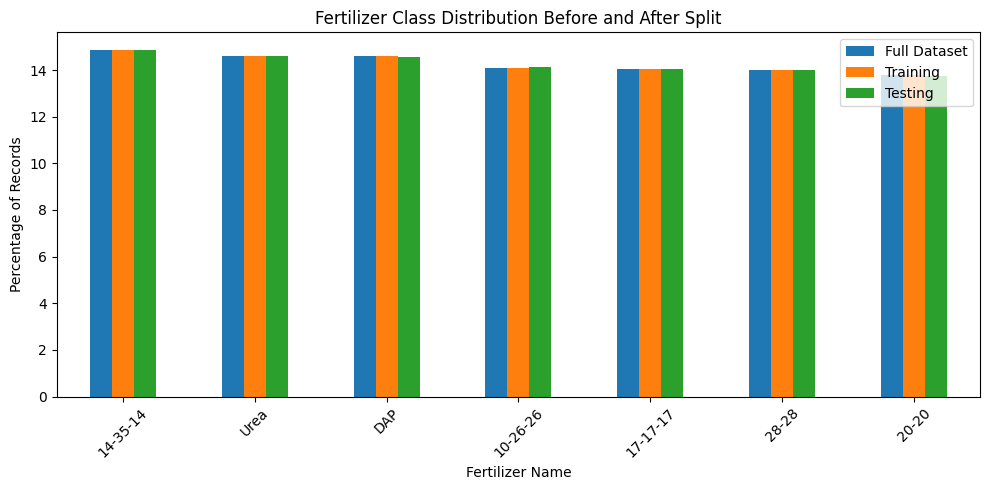

In [5]:
X = df.drop(columns=["Fertilizer Name"])
y = df["Fertilizer Name"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

distribution = pd.concat(
    [
        y.value_counts(normalize=True).rename("Full Dataset"),
        y_train.value_counts(normalize=True).rename("Training"),
        y_test.value_counts(normalize=True).rename("Testing")
    ],
    axis=1
) * 100

print(distribution.round(2))

distribution.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Percentage of Records")
plt.title("Fertilizer Class Distribution Before and After Split")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOT_DIR / "class_distribution_split.png")
plt.show()

## 3. Categorical Feature EDA


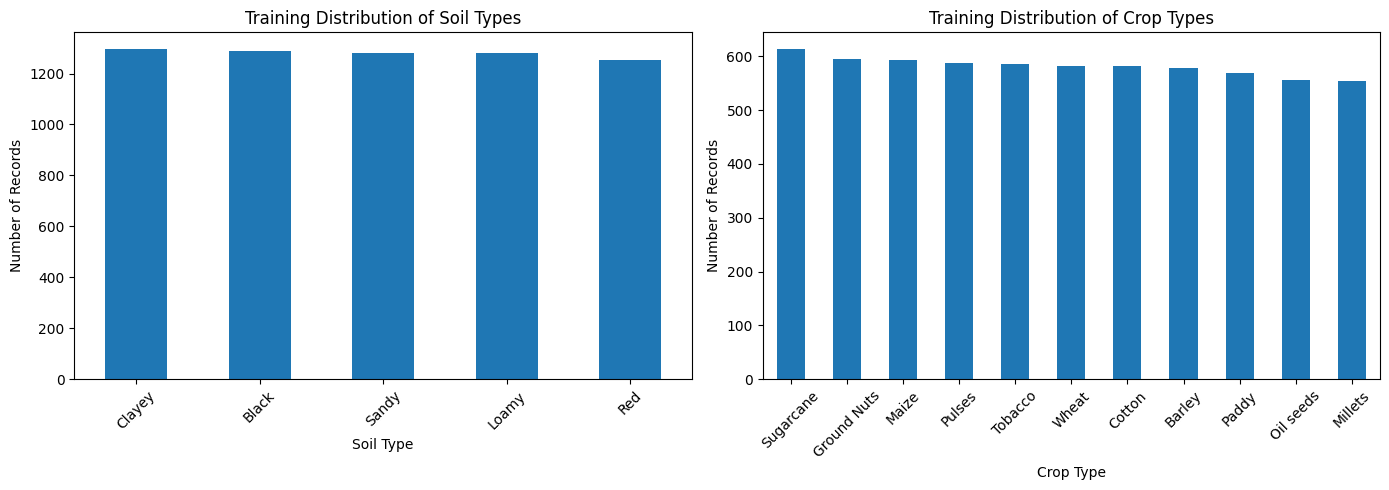

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

X_train["Soil Type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Training Distribution of Soil Types")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=45)

X_train["Crop Type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Training Distribution of Crop Types")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(PLOT_DIR / "categorical_distributions.png")
plt.show()

## 4. Feature Engineering


In [7]:
def add_engineered_features(X):
    X = X.copy()

    X["Total_Nutrients"] = (
        X["Nitrogen"]
        + X["Phosphorous"]
        + X["Potassium"]
    )

    X["NPK_Imbalance"] = (
        X[["Nitrogen", "Phosphorous", "Potassium"]].max(axis=1)
        - X[["Nitrogen", "Phosphorous", "Potassium"]].min(axis=1)
    )

    return X

X_train_work = add_engineered_features(X_train)
X_test_work = add_engineered_features(X_test)

X_train_work[
    ["Nitrogen", "Phosphorous", "Potassium",
     "Total_Nutrients", "NPK_Imbalance"]
].head()

,Nitrogen,Phosphorous,Potassium,Total_Nutrients,NPK_Imbalance
2894,9,44,4,57,40
346,11,9,0,20,11
641,10,10,0,20,10
2242,9,17,4,30,13
3977,41,1,1,43,40


## 5. Outlier Detection


    Feature  Q1 (train)  Q3 (train)  Lower Bound  Upper Bound  Train Flagged  Train Flagged (%)  Test Flagged
Temparature       27.09       33.49        17.49        43.09              0               0.00             0
   Humidity       53.45       65.03        36.07        82.40              0               0.00             0
   Moisture       33.90       52.88         5.43        81.35              0               0.00             0
   Nitrogen        9.00       26.00       -16.50        51.50              0               0.00             0
  Potassium        0.00        5.00        -7.50        12.50            732              11.44           178
Phosphorous        8.00       30.00       -25.00        63.00              0               0.00             0

Decision: no rows are removed. Potassium has 732 training observations flagged by the IQR rule, while the other original numerical features have no IQR flags. These values are retained because statistical outliers are not automat

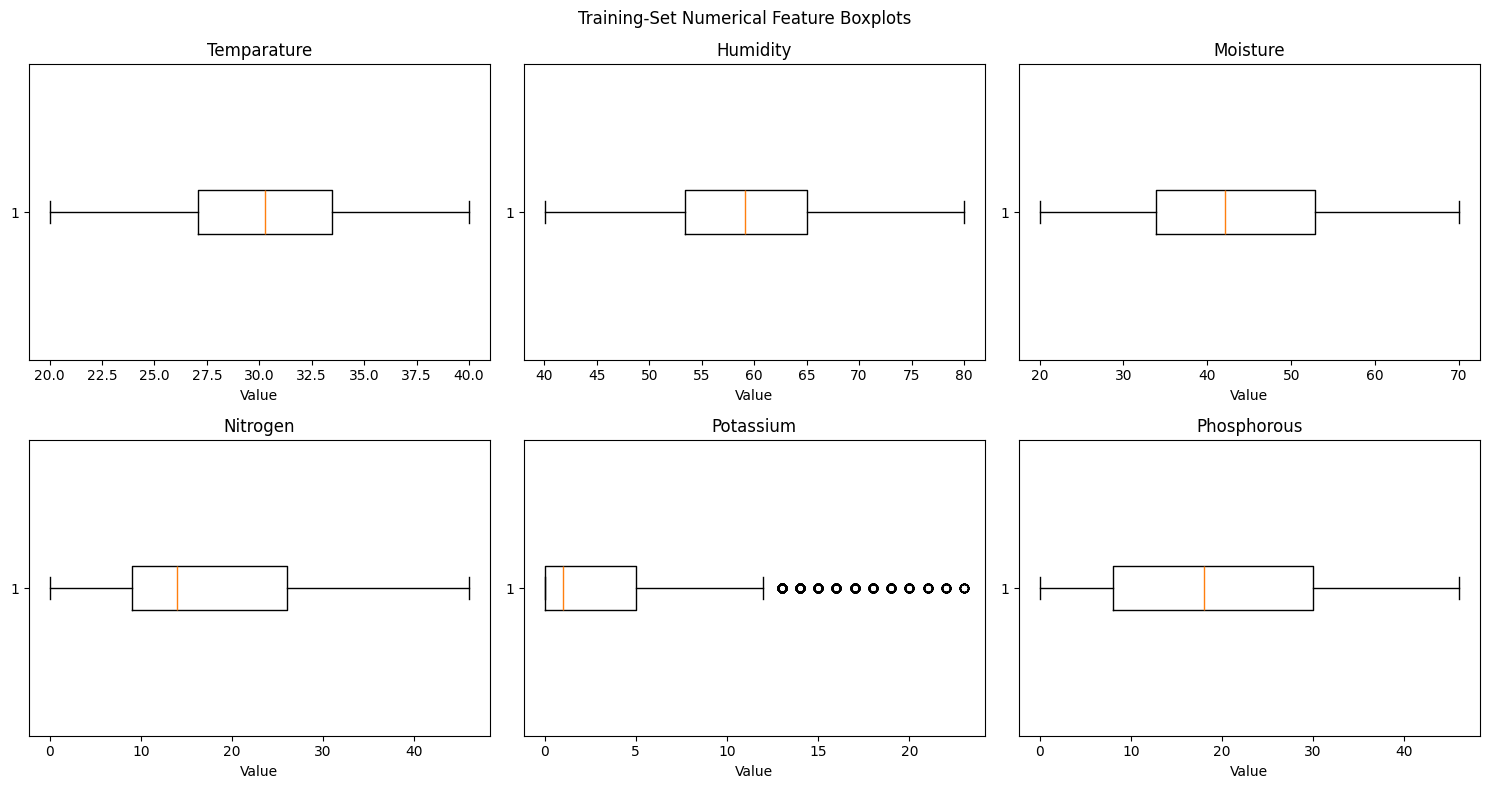

In [8]:
numeric_original = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous"
]

outlier_rows = []

for column in numeric_original:
    Q1 = X_train_work[column].quantile(0.25)
    Q3 = X_train_work[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    train_flagged = (
        (X_train_work[column] < lower_bound)
        | (X_train_work[column] > upper_bound)
    )

    # Test flags are reported using TRAINING bounds only.
    test_flagged = (
        (X_test_work[column] < lower_bound)
        | (X_test_work[column] > upper_bound)
    )

    outlier_rows.append({
        "Feature": column,
        "Q1 (train)": Q1,
        "Q3 (train)": Q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Train Flagged": int(train_flagged.sum()),
        "Train Flagged (%)": 100 * train_flagged.mean(),
        "Test Flagged": int(test_flagged.sum())
    })

outlier_summary = pd.DataFrame(outlier_rows)
print(outlier_summary.round(2).to_string(index=False))

potassium_flags = outlier_summary.loc[
    outlier_summary["Feature"] == "Potassium",
    "Train Flagged"
].iloc[0]

print(
    f"\nDecision: no rows are removed. Potassium has {potassium_flags} "
    "training observations flagged by the IQR rule, while the other original "
    "numerical features have no IQR flags. These values are retained because "
    "statistical outliers are not automatically invalid observations."
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, column in zip(axes, numeric_original):
    ax.boxplot(X_train_work[column], vert=False)
    ax.set_title(column)
    ax.set_xlabel("Value")

plt.suptitle("Training-Set Numerical Feature Boxplots")
plt.tight_layout()
plt.savefig(PLOT_DIR / "numeric_outlier_boxplots.png")
plt.show()

## 6. Correlation and Feature Redundancy Analysis


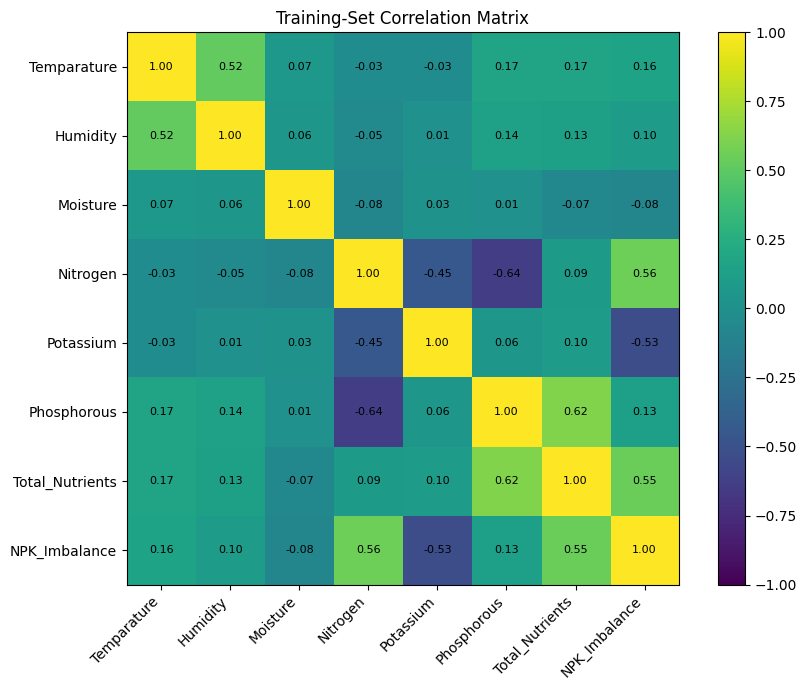

Feature pairs with |correlation| >= 0.85:
None

Is Total_Nutrients an exact N + P + K sum? True
Decision: Total_Nutrients removed from model inputs due to exact redundancy.
NPK_Imbalance retained as an engineered feature.
Model-input columns: ['Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'NPK_Imbalance']


In [9]:
numeric_with_engineered = numeric_original + [
    "Total_Nutrients",
    "NPK_Imbalance"
]

corr = X_train_work[numeric_with_engineered].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

fig.colorbar(image)
plt.title("Training-Set Correlation Matrix")
plt.tight_layout()
plt.savefig(PLOT_DIR / "correlation_heatmap.png")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = upper.stack()[upper.stack().abs() >= 0.85]

print("Feature pairs with |correlation| >= 0.85:")
print(high_corr if len(high_corr) else "None")

total_check = (
    X_train_work["Nitrogen"]
    + X_train_work["Phosphorous"]
    + X_train_work["Potassium"]
)

is_exact_sum = np.allclose(
    X_train_work["Total_Nutrients"].to_numpy(),
    total_check.to_numpy()
)

print("\nIs Total_Nutrients an exact N + P + K sum?", is_exact_sum)

if is_exact_sum:
    X_train_model = X_train_work.drop(columns=["Total_Nutrients"])
    X_test_model = X_test_work.drop(columns=["Total_Nutrients"])
    print("Decision: Total_Nutrients removed from model inputs due to exact redundancy.")
else:
    X_train_model = X_train_work.copy()
    X_test_model = X_test_work.copy()

print("NPK_Imbalance retained as an engineered feature.")
print("Model-input columns:", X_train_model.columns.tolist())

## 7. Target Encoding


In [10]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

target_mapping = pd.DataFrame({
    "Fertilizer Name": label_encoder.classes_,
    "Encoded Label": label_encoder.transform(label_encoder.classes_)
})

target_mapping

,Fertilizer Name,Encoded Label
0,10-26-26,0
1,14-35-14,1
2,17-17-17,2
3,20-20,3
4,28-28,4
5,DAP,5
6,Urea,6


## 8. Feature Encoding and Scaling


In [11]:
numeric_features = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
    "NPK_Imbalance"
]

categorical_features = [
    "Soil Type",
    "Crop Type"
]

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", one_hot, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train_model)
X_test_processed = preprocessor.transform(X_test_model)

feature_names = preprocessor.get_feature_names_out()

print("Model-input training features:", X_train_model.shape[1])
print("Processed training features:", X_train_processed.shape[1])
print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])

Model-input training features: 9
Processed training features: 23
Training rows: 6400
Testing rows: 1600


## 9. Final Processed Outputs

In [12]:
train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

train_processed["Fertilizer_Label"] = y_train_encoded
test_processed["Fertilizer_Label"] = y_test_encoded

train_processed.to_csv(
    OUTPUT_DIR / "train_processed.csv",
    index=False
)

test_processed.to_csv(
    OUTPUT_DIR / "test_processed.csv",
    index=False
)

target_mapping.to_csv(
    OUTPUT_DIR / "fertilizer_label_mapping.csv",
    index=False
)

outlier_summary.to_csv(
    OUTPUT_DIR / "outlier_summary.csv",
    index=False
)

print("Processed training data:", train_processed.shape)
print("Processed testing data:", test_processed.shape)

print("\nSaved outputs:")
print("- results/outputs/train_processed.csv")
print("- results/outputs/test_processed.csv")
print("- results/outputs/fertilizer_label_mapping.csv")
print("- results/outputs/outlier_summary.csv")

train_processed.head()

Processed training data: (6400, 24)
Processed testing data: (1600, 24)

Saved outputs:
- results/outputs/train_processed.csv
- results/outputs/test_processed.csv
- results/outputs/fertilizer_label_mapping.csv
- results/outputs/outlier_summary.csv


,numeric__Temparature,numeric__Humidity,numeric__Moisture,numeric__Nitrogen,numeric__Potassium,numeric__Phosphorous,numeric__NPK_Imbalance,categorical__Soil Type_Black,categorical__Soil Type_Clayey,categorical__Soil Type_Loamy,...,categorical__Crop Type_Ground Nuts,categorical__Crop Type_Maize,categorical__Crop Type_Millets,categorical__Crop Type_Oil seeds,categorical__Crop Type_Paddy,categorical__Crop Type_Pulses,categorical__Crop Type_Sugarcane,categorical__Crop Type_Tobacco,categorical__Crop Type_Wheat,Fertilizer_Label
0,0.372128,0.464596,-0.706641,-0.796927,0.010998,1.916286,1.260013,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,3
1,-0.048158,1.100487,-0.490063,-0.627633,-0.714630,-0.722512,-1.217459,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4
2,-1.089931,-0.044854,-1.255251,-0.712280,-0.714630,-0.647118,-1.302889,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.150807,-1.742610,-0.982936,-0.796927,0.010998,-0.119359,-1.046598,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,4
4,0.463786,1.186418,0.500461,1.911785,-0.533223,-1.325666,1.260013,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2
